# Selección de variables

**Objetivo.** Elegir, entre las predictoras del preprocesamiento y las variables derivadas del frío, un subconjunto manejable e informativo para pronosticar al cierre de **D** el consumo de frío de **D+1**.

**Entrada.** `data/processed/historial_completo.csv`, generado por `src/preprocessing_pipeline.py` (ver `notebooks/preprocesamiento.ipynb`) a partir de las columnas que dejó la EDA. Los componentes del frío y los medidores que lo contienen ya no están entre las candidatas. Se verifica su SHA-256 antes de usarlo.

**Métodos** (cada uno es una función independiente en `src/preprocessing_pipeline.py`):

| Método | Qué mide | Cómo decide cuántas variables |
|---|---|---|
| Mutual Information | Dependencia (también no lineal) de cada variable con `y`, por separado | Curva k → MAE interno, regla de un error estándar |
| Ridge | \|coeficiente\| de una regresión Ridge con variables estandarizadas | Curva k → MAE interno, regla de un error estándar |
| Lasso | Coeficientes que la penalización L1 deja distintos de cero | El alpha de `LassoCV` |
| Forward | Agrega de a una la variable que más baja el MAE interno | Se detiene si la mejora es < 5 kW (máximo 25 variables) |

**Reglas contra la fuga de información:**

1. Todo método, y el filtro de redundancia previo, se ajusta **solo con Train**. Para elegir hiperparámetros y cantidad de variables se usa una **validación temporal interna** (`TimeSeriesSplit`, 5 bloques, con un día de hueco).
2. **Validation** se usa una sola vez: para comparar los subconjuntos finales entre sí y contra los baselines.
3. **Test no se lee** en esta notebook.
4. Las variables del frío (rezagos, medias móviles, desvío, diferencia) usan solo días ≤ D.
5. Los cortes del binning, la media y el desvío de las interacciones y los topes de los ratios se estiman **solo con Train**. El ciclo anual depende solo de la fecha.

| Sección | Contenido |
|---|---|
| 1 | Datos y candidatas, con las variables creadas: ciclo anual (1.1), binning (1.2), interacciones (1.3), ratios entre áreas y eficiencia contra la meta (1.4), y el filtro de redundancia (1.5) |
| 2 | Validación temporal interna |
| 3 | Mutual Information |
| 4 | Ridge |
| 5 | Lasso |
| 6 | Forward selection |
| 7 | Coincidencias entre métodos |
| 8 | Comparación en Validation y aporte de las variables creadas (8.1) |
| 9 | Exportación y comparación con el script |
| 10 | Conclusiones |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from src import auxiliar_functions as af
from src import preprocessing_pipeline as pp

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

COLORES = {"mutual_information": "#2a78d6", "ridge": "#eb6834", "lasso": "#1baf7a",
           "forward": "#eda100", "consenso_2_metodos": "#e87ba4", "todas": "#52514e"}
plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

def corto(nombre, largo=42):
    # Nombre legible: sin el sufijo de la hoja y recortado.
    base = nombre.rsplit("_", 1)[0] if "_" in nombre and not nombre.startswith(("frio_", "mes_", "dia_", "fin_", "anio_", "bin_", "int_", "maq_")) else nombre
    return base if len(base) <= largo else base[:largo - 1] + "…"

cfg = pp.ConfigSeleccion()
display(pd.Series(vars(cfg), name="valor").to_frame())

,valor
rezagos_frio,"(1, 2, 3, 4, 5, 6, 7, 14)"
ventanas_media_frio,"(2, 3, 5, 7, 10, 14, 21, 28)"
ventanas_mediana_frio,"(3, 7, 14)"
ventanas_desvio_frio,"(3, 7, 14)"
ventanas_extremos_frio,"(3, 7, 14)"
spans_media_exponencial_frio,"(3, 7, 14)"
diferencias_frio,"(1, 2, 3, 7)"
max_arrastre_dias,3
incluir_calendario,True
armonicos_anuales,"(1, 2)"


## 1. Datos y candidatas

Las candidatas son:

* **Predictoras del preprocesamiento:** mediciones diarias limpias, imputadas y sin escalar, más los indicadores de imputación.
* **Variables del frío:** el frío de hoy ya está entre las predictoras. Se agregan varias familias, para que la selección decida qué memoria del consumo sirve:

  | Familia | Nombre | Ventanas o rezagos |
  |---|---|---|
  | Rezago | `frio_lag_k` (frío de D-k) | 1, 2, 3, 4, 5, 6, 7 y 14 días |
  | Media móvil | `frio_media_v` | 2, 3, 5, 7, 10, 14, 21 y 28 cierres |
  | Mediana móvil (robusta a un día atípico) | `frio_mediana_v` | 3, 7 y 14 cierres |
  | Desvío móvil (variabilidad reciente) | `frio_desvio_v` | 3, 7 y 14 cierres |
  | Mínimo y máximo de la ventana | `frio_min_v`, `frio_max_v` | 3, 7 y 14 cierres |
  | Media exponencial (pesa más lo reciente) | `frio_ewm_s` | span 3, 7 y 14 |
  | Diferencia (tendencia) | `frio_diff_k` (frío de D menos frío de D-k) | 1, 2, 3 y 7 días |

  Faltan 40 días calendario: 17 los descartó la limpieza y 23 no existen en ningún Excel. Los rezagos y diferencias se miden en días calendario y, si falta un día, toman el último cierre anterior (hasta 3 días de arrastre). Las ventanas usan los últimos *v* cierres observados, así nunca quedan vacías.
* **Calendario:** `mes` (1 a 12, útil para los árboles), mes y día de la semana con codificación cíclica (seno y coseno, útil para los modelos lineales: diciembre y enero quedan cerca) e indicador de fin de semana.
* **Variables creadas.** La evidencia que las motiva está en la sección 13 del preprocesamiento.

  | Familia | Nombre | Qué representa | Se estima con Train |
  |---|---|---|---|
  | Ciclo anual | `anio_sin_k`, `anio_cos_k` (k = 1, 2) | Posición del día en el año, continua y circular | Nada |
  | Binning | `bin_<var>_q<i>`, `bin_mosto_cero` | En qué intervalo de cuantiles cae el frío de D (5), bodega, envasada o mosto (4) | Los cortes |
  | Interacción | `int_<a>_x_<b>` | Producto de a pares entre frío D, bodega, envasada y mosto, y de cada uno con el ciclo anual | Media y desvío |
  | Ratio entre áreas | `ratio_<a>_<b>`, `sin_produccion_<hl>` | Cocientes entre consumos de distintas áreas y por hectolitro producido; indicador de día sin producción | Topes (percentiles 0,5 y 99,5) |
  | Eficiencia contra la meta | `efic_<área>_vs_meta` | Consumo por hectolitro del día dividido por la meta del mes (hoja *Consolidado KPI*) | Topes (percentiles 0,5 y 99,5) |

  La familia de maquinaria funcionando (`maq_*`) de la versión anterior ya no se crea: se construía con los compresores Mycom y los condensadores, que la EDA excluye porque son componentes del frío.

In [2]:
historial = pp.cargar_preprocesado()
candidatas, creadas = pp.construir_candidatas_y_ajuste(historial, cfg)
datos = pp.particiones(historial, candidatas)
X_tr, y_tr, perdidas_tr = datos["train"]
X_val, y_val, perdidas_val = datos["validation"]

familia = pd.Series({c: pp.familia_de(c) for c in candidatas.columns}, name="familia")
CREADAS = ["ciclo anual", "binning", "interacción", "ratio entre áreas", "eficiencia vs meta"]
display(familia.value_counts().rename_axis("Familia").to_frame("Candidatas"))
derivadas_frio = familia.index[familia == "derivada del frío"]
familia_frio = pd.Series(derivadas_frio, index=derivadas_frio).str.extract(r"frio_([a-z]+)_")[0]
display(familia_frio.value_counts().rename_axis("Familia derivada del frío").to_frame("Variables"))

print(f"Train: {len(X_tr)} filas ({X_tr.index.min().date()} a {X_tr.index.max().date()}), "
      f"{perdidas_tr} sin historia suficiente al comienzo de la serie")
print(f"Validation: {len(X_val)} filas ({X_val.index.min().date()} a {X_val.index.max().date()}), "
      f"{perdidas_val} descartadas")

,Candidatas
Familia,
preprocesamiento,269
derivada del frío,35
binning,17
interacción,14
ratio entre áreas,11
calendario,6
ciclo anual,4
eficiencia vs meta,4


,Variables
Familia derivada del frío,
lag,8
media,8
diff,4
mediana,3
desvio,3
min,3
max,3
ewm,3


Train: 786 filas (2020-07-15 a 2022-10-26), 12 sin historia suficiente al comienzo de la serie
Validation: 171 filas (2022-10-27 a 2023-04-29), 0 descartadas


In [3]:
# Control de causalidad de TODAS las candidatas: construirlas con la historia cortada en una fecha
# da los mismos valores hasta esa fecha. Los cortes son posteriores al fin de Train, así que el
# binning y las interacciones se ajustan con los mismos días en los dos casos.
for corte in (X_val.index.min(), X_val.index[len(X_val) // 2]):
    parcial = pp.construir_candidatas(historial.loc[:corte], cfg)
    pd.testing.assert_frame_equal(candidatas.loc[:corte], parcial)
    print(f"Candidatas causales: calcularlas con datos hasta {corte.date()} da el mismo resultado.")

Candidatas causales: calcularlas con datos hasta 2022-10-27 da el mismo resultado.
Candidatas causales: calcularlas con datos hasta 2023-01-26 da el mismo resultado.


### 1.1 Variables circulares anuales

Codificar el día del año como número (1 a 365) deja al 31 de diciembre lejos del 1 de enero, aunque son días vecinos. Proyectarlo sobre un círculo con seno y coseno lo resuelve: los dos valores juntos ubican cada día en el año, sin saltos.

* Con seno y coseno juntos, un modelo lineal representa una onda anual con **cualquier fase**: a·sen(2πt) + b·cos(2πt) = A·cos(2πt − φ). No hace falta decidir de antemano cuándo es "verano"; conviene, porque el pico del frío (principios de junio) no coincide con el de la temperatura (mediados de agosto).
* El **armónico 2** (k = 2) agrega una onda semestral, que permite que la subida y la bajada de la estación tengan formas distintas.
* `mes_sin` y `mes_cos` ya existían, pero son constantes dentro de cada mes; las nuevas cambian día a día.

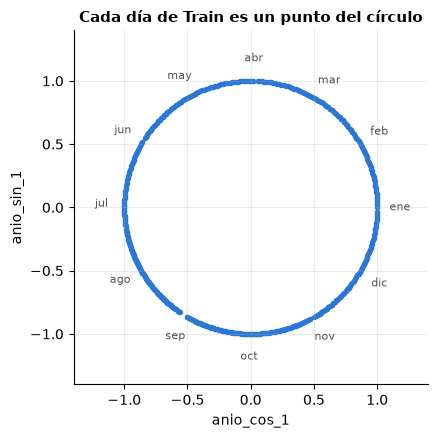

,familia,Spearman con y,información mutua con y
mes,calendario,-0.084,0.605
mes_sin,calendario,0.294,0.242
mes_cos,calendario,-0.720,0.428
anio_sin_1,ciclo anual,0.051,0.327
anio_cos_1,ciclo anual,-0.804,0.640
anio_sin_2,ciclo anual,0.005,0.051
anio_cos_2,ciclo anual,-0.073,0.281


In [4]:
fin_train = pp.fin_de_ajuste(historial)
anual = candidatas.loc[:fin_train, ["anio_sin_1", "anio_cos_1"]]
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(anual["anio_cos_1"], anual["anio_sin_1"], s=8, color="#2a78d6")
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
inicio_mes = pp.variables_ciclo_anual(pd.date_range("2021-01-01", periods=12, freq="MS"), (1,))
for nombre, (s, c) in zip(meses, inicio_mes[["anio_sin_1", "anio_cos_1"]].to_numpy()):
    ax.annotate(nombre, (c, s), xytext=(c * 1.18, s * 1.18), ha="center", va="center", fontsize=8,
                color="#52514e")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.set_aspect("equal")
ax.set_xlabel("anio_cos_1")
ax.set_ylabel("anio_sin_1")
ax.set_title("Cada día de Train es un punto del círculo")
plt.show()

from sklearn.feature_selection import mutual_info_regression
circulares = ["mes", "mes_sin", "mes_cos", "anio_sin_1", "anio_cos_1", "anio_sin_2", "anio_cos_2"]
display(pd.DataFrame({
    "familia": familia[circulares],
    "Spearman con y": X_tr[circulares].corrwith(y_tr, method="spearman"),
    "información mutua con y": mutual_info_regression(X_tr[circulares], y_tr, n_neighbors=cfg.mi_vecinos,
                                                      random_state=pp.SEMILLA),
}).round(3))

### 1.2 Binning

El binning divide una variable continua en intervalos y crea un indicador 0/1 por intervalo. Así un modelo lineal puede representar una relación por tramos: en la sección 13 del preprocesamiento, el residuo de `y` después de la persistencia lineal cambiaba de signo entre quintiles del frío de hoy.

* Los cortes son **cuantiles de Train** (intervalos con la misma cantidad de días) y quedan fijos en `fit`. En Validation y Test, un valor fuera del rango de Train cae en el intervalo extremo.
* Si más del 5 % de los días de Train son cero (sin producción), el cero es un intervalo propio y los cuantiles se calculan sobre los valores positivos. Pasa con el mosto: 8 % de días sin cocimiento.
* Se conservan todos los indicadores y la selección decide cuáles sirven.

In [5]:
tabla_bins = creadas.reporte_.query("familia == 'binning'").set_index("variable")
tabla_bins["y medio en Train (kW)"] = [y_tr[X_tr[v] == 1].mean() for v in tabla_bins.index]
display(tabla_bins[["definicion", "pct_dias_train", "y medio en Train (kW)"]]
        .rename(columns={"definicion": "intervalo", "pct_dias_train": "% días de Train"}).round(1))

,intervalo,% días de Train,y medio en Train (kW)
variable,,,
bin_frio_q1,"frio < 17,771",20.0,14202.1
bin_frio_q2,"17,771 <= frio < 23,691",20.0,22216.0
bin_frio_q3,"23,691 <= frio < 27,721",19.9,25851.8
bin_frio_q4,"27,721 <= frio < 31,673",20.0,29611.2
bin_frio_q5,"frio >= 31,673",20.0,32706.2
bin_bodega_q1,"bodega < 7,349",25.0,18604.1
bin_bodega_q2,"7,349 <= bodega < 9,812",24.9,24103.1
bin_bodega_q3,"9,812 <= bodega < 11,603",25.0,27800.0
bin_bodega_q4,"bodega >= 11,603",25.0,28851.7


### 1.3 Interacciones

Una interacción (el producto de dos variables) permite que el efecto de una dependa del valor de la otra. La sección 13 del preprocesamiento mostró dos casos: la persistencia del frío es más débil en la mitad cálida del año, y la producción aporta más en la mitad fría.

* **Entre variables principales:** frío D, Hl de bodega, Hl envasados y Hl de mosto (entrada a fermentación), las que la sección 11 del preprocesamiento identificó como más relacionadas con el frío. Se multiplican de a pares (6 productos).
* **Con el ciclo anual:** cada una por `anio_sin_1` y por `anio_cos_1` (8 productos). Con el par seno y coseno, el modelo elige en qué época del año el efecto es mayor.
* Antes de multiplicar, cada variable se **estandariza con la media y el desvío de Train**. Sin centrar, el producto de dos variables positivas crece con cada una y queda casi colineal con sus factores, y la selección no podría separar la interacción de los efectos principales. La tabla lo muestra.

In [6]:
filas = []
for _, fila in creadas.reporte_.query("familia == 'interacción'").iterrows():
    a, b = fila["origen"].split(" × ")
    centrada, sin_centrar = X_tr[fila["variable"]], X_tr[a] * X_tr[b]
    filas.append({
        "interacción": fila["variable"],
        "Spearman con y": centrada.corr(y_tr, method="spearman"),
        "máx. |Spearman| con sus factores": max(abs(centrada.corr(X_tr[c], method="spearman")) for c in (a, b)),
        "ídem, producto sin centrar": max(abs(sin_centrar.corr(X_tr[c], method="spearman")) for c in (a, b)),
    })
display(pd.DataFrame(filas).set_index("interacción").round(2))

,Spearman con y,máx. |Spearman| con sus factores,"ídem, producto sin centrar"
interacción,,,
int_frio_x_bodega,-0.10,0.09,0.89
int_frio_x_envasada,-0.07,0.07,0.88
int_frio_x_mosto,0.07,0.13,0.82
int_bodega_x_envasada,-0.10,0.07,0.93
int_bodega_x_mosto,-0.01,0.06,0.94
int_envasada_x_mosto,0.06,0.24,0.76
int_frio_x_anio_sin_1,-0.05,0.11,0.96
int_frio_x_anio_cos_1,0.10,0.09,0.95
int_bodega_x_anio_sin_1,-0.07,0.20,0.94


### 1.4 Ratios entre áreas y eficiencia contra la meta

La consigna sugiere dos familias que la versión anterior no tenía:

* **Ratios entre consumos de distintas áreas**, y por hectolitro producido. Se eligieron ratios de la operación que vinculan el frío con la producción (mosto, cerveza en bodega y envasada) y que pueden calcularse con las columnas que dejó la EDA, más tres cocientes entre áreas de energía eléctrica.
* **Eficiencia energética contra la meta:** consumo por hectolitro del día dividido por la meta del mes (columnas `Meta` de *Consolidado KPI*). Un valor mayor a 1 indica que ese día se consumió por hectolitro más de lo que fija la meta.

Cómo se calculan:

* Con valores del día D: no usan días futuros.
* Si el denominador es ≤ 0 (un día sin producción), el cociente vale 0, y para los denominadores de producción un indicador `sin_produccion_*` marca esos días. No se suma un épsilon al denominador, como suele proponerse: con producción 0 daría valores del orden de 10⁹ que dominan cualquier modelo.
* Con denominadores chicos el cociente tiene colas extremas, así que se recorta a los percentiles 0,5 y 99,5 de Train.

In [7]:
tabla_cocientes = creadas.reporte_[creadas.reporte_["familia"].isin(["ratio entre áreas", "eficiencia vs meta"])]
cocientes = tabla_cocientes["variable"].tolist()

# Lo que el frío de hoy y su media de 7 días no explican de y (regresión lineal en Train).
persistencia = X_tr[[pp.COL_FRIO, "frio_media_7"]]
A = np.c_[np.ones(len(persistencia)), persistencia.to_numpy()]
residuo = y_tr - A @ np.linalg.lstsq(A, y_tr.to_numpy(), rcond=None)[0]

display(tabla_cocientes.set_index("variable")[["familia", "definicion", "pct_dias_train"]]
        .assign(**{"Spearman con y": X_tr[cocientes].corrwith(y_tr, method="spearman"),
                   "Spearman con lo no explicado": X_tr[cocientes].corrwith(residuo, method="spearman")})
        .round(3))

,familia,definicion,pct_dias_train,Spearman con y,Spearman con lo no explicado
variable,,,,,
ratio_bodega_elaboracion_kw,ratio entre áreas,Bodega (Kw) / Elaboracion (Kw) (0 si el denominador <= 0; recortad...,100.000,0.037,-0.051
ratio_frio_elaboracion_kw,ratio entre áreas,Frio (Kw) / Elaboracion (Kw) (0 si el denominador <= 0; recortado ...,100.000,0.517,0.024
ratio_frio_envasado_kw,ratio entre áreas,Frio (Kw) / Envasado (Kw) (0 si el denominador <= 0; recortado a [...,100.000,0.240,-0.130
ratio_frio_por_hl_mosto,ratio entre áreas,Frio (Kw) / Hl de Mosto (0 si el denominador <= 0; recortado a [1....,91.819,0.490,-0.028
ratio_mosto_envasada,ratio entre áreas,Hl de Mosto / Hl Cerveza Envasada (0 si el denominador <= 0; recor...,96.947,0.024,-0.035
ratio_agua_bodega_por_hl,ratio entre áreas,Agua Bodega (Hl) / Hl Producido Bodega (0 si el denominador <= 0; ...,98.901,-0.264,-0.204
ratio_agua_elab_por_hl_mosto,ratio entre áreas,Agua Elaboracion (Hl) / Hl de Mosto (0 si el denominador <= 0; rec...,91.819,0.156,-0.088
ratio_et_elab_por_hl_mosto,ratio entre áreas,ET Elaboracion (Mj) / Hl de Mosto (0 si el denominador <= 0; recor...,91.819,-0.007,-0.030
efic_frio_vs_meta,eficiencia vs meta,EE Frio / Hl / Meta EE Frio (0 si el denominador <= 0; recortado a...,100.000,0.324,-0.118


**Lectura (Train):**

* **Los cocientes que contienen al frío** (frío por kW de elaboración, frío por hectolitro de mosto) se relacionan con `y` (alrededor de 0,5) solo porque contienen al frío de D. Frente a lo que no explica la persistencia, su correlación es casi nula.
* **Los que más aportan sobre la persistencia** son agua de bodega por hectolitro (alrededor de −0,21), las cuatro eficiencias contra la meta (−0,10 a −0,15) y frío por kW de envasado (−0,13). El signo de agua de bodega es el contrario al que propone el documento de ratios: los días con más agua por hectolitro en bodega (limpiezas) anticipan un frío de mañana por debajo de lo que predice la persistencia.
* **Los indicadores de días sin producción** no aportan sobre la persistencia.

### 1.5 Filtro de redundancia (probado y desactivado)

Muchas candidatas repiten casi la misma información: hay 35 ventanas del frío, decenas de metas que cambian juntas una vez por año, y medidores que siguen al mismo nivel de actividad. Para reducir esa redundancia se implementó un filtro ajustado **solo con Train**, que se aplica antes de los métodos:

1. Las candidatas se ordenan por |Spearman| con `y`. El frío de D va primero y siempre se conserva.
2. Se recorren en ese orden y se descarta cada una que tenga |Spearman| ≥ umbral con alguna ya conservada.
3. Las constantes en Train se descartan.

El umbral está en `ConfigSeleccion.umbral_redundancia` y **por defecto está desactivado** (`None`). Se probó con 0,90 en `comparar_variantes()` de `src/auxiliar_functions.py`, que repite la selección y el modelado y mide solo en Validation. La celda siguiente aplica la configuración vigente y muestra el resultado de esa prueba.

In [8]:
columnas_filtradas, redundancia = pp.filtrar_redundantes(X_tr, y_tr, cfg)
X_tr, X_val = X_tr[columnas_filtradas], X_val[columnas_filtradas]
familia = familia[columnas_filtradas]
print(f"umbral_redundancia = {cfg.umbral_redundancia} | candidatas que siguen: {len(columnas_filtradas)}")

# Prueba con umbral 0,90 (comparar_variantes() de src/auxiliar_functions.py): candidatas que quedarían y efecto en Validation.
prueba = pp.ConfigSeleccion(umbral_redundancia=0.90)
quedarian, reporte_prueba = pp.filtrar_redundantes(X_tr, y_tr, prueba)
print(f"Con umbral 0,90 quedarían {len(quedarian)} de {len(columnas_filtradas)} candidatas. "
      "Las que más candidatas representarían:")
descartables = reporte_prueba[reporte_prueba["decision"] == "descartar"]
display(descartables.groupby("redundante_con")["columna"].agg(["count", lambda s: ", ".join(s.head(4))])
        .set_axis(["descartadas", "ejemplos"], axis=1).sort_values("descartadas", ascending=False).head(6))
comparacion_variantes = af.comparar_variantes()["mejoras"]  # repite selección y búsqueda con cada variante (unos minutos)
print("Ganador de cada modelo en Validation, sin filtro y con filtro 0,90 (Optuna eligiendo el objetivo):")
display(comparacion_variantes.sort_values(["filtro", "mae_val"]).round(1))

umbral_redundancia = None | candidatas que siguen: 360


Con umbral 0,90 quedarían 265 de 360 candidatas. Las que más candidatas representarían:


,descartadas,ejemplos
redundante_con,,
Meta EE Planta_Consolidado KPI,22,"Meta Aire Planta_Consolidado KPI, Meta EE Elaboracion_Consolidado ..."
frio_ewm_14,15,"frio_media_10, frio_media_14, frio_media_7, frio_media_5"
Meta Agua Planta_Consolidado KPI,9,"Meta Agua Elab_Consolidado KPI, Meta Agua Bodega_Consolidado KPI, ..."
Meta ET Planta_Consolidado KPI,9,"Meta ET Elab_Consolidado KPI, Meta ET Bodega_Consolidado KPI, Meta..."
Frio (Kw)_Consolidado EE,5,"frio_ewm_3, frio_ewm_7, frio_media_2, frio_media_3"
KW Trafo 8_Totalizadores Energia,3,"Linea 2 (Kw)_Consolidado EE, KW Linea 2_Totalizadores Energia, Hl ..."


Ganador de cada modelo en Validation, sin filtro y con filtro 0,90 (Optuna eligiendo el objetivo):


,filtro,modelo,conjunto,objetivo,n_columnas,mae_interno,mae_val,sesgo_val
5,filtro 0.9,LightGBM,todas,cambio_media7,266,3071.1,2371.7,728.7
6,filtro 0.9,XGBoost,todas,cambio_media7,266,3062.0,2409.9,627.9
7,filtro 0.9,Random Forest,forward,cambio_media7,21,3052.0,2489.3,508.9
8,filtro 0.9,Ridge,forward,cambio_media7,21,2916.0,2519.5,909.9
9,filtro 0.9,Lasso,consenso_2_metodos,nivel,20,2903.7,2573.1,1235.4
0,sin filtro,Random Forest,ridge,cambio_media7,121,3042.7,2327.0,304.0
1,sin filtro,LightGBM,todas,cambio_media7,360,3056.6,2366.4,623.6
2,sin filtro,Lasso,forward,cambio_media7,24,2816.6,2397.8,428.9
3,sin filtro,Ridge,forward,nivel,23,2809.1,2467.0,481.1
4,sin filtro,XGBoost,ridge,cambio,120,3061.5,2560.3,1236.7


**Lectura y decisión:**

* Con umbral 0,90 el filtro deja 265 de las 360 candidatas. `frio_ewm_14` representa a 15 medias y medianas del frío, y `Meta EE Planta` a 22 metas que cambian juntas.
* **Pero empeora en Validation en todos los modelos.** El mejor pasa de 2.327 a 2.372 kW, y los sesgos crecen (Ridge con forward sobreestima 910 kW en lugar de 481). El filtro saca ventanas que sí sirven, como la media de 10 cierres y el mínimo de 14, y el ciclo anual `anio_cos_1`.
* **Decisión: queda desactivado.** El código se conserva para documentar la prueba y poder repetirla con otro umbral.

## 2. Validación temporal interna

Dentro de Train, `TimeSeriesSplit` arma 5 bloques: cada uno se ajusta con el pasado y se evalúa con el período siguiente. El **hueco de un día** evita que el último `y` del ajuste (el frío del día siguiente) sea a la vez la predictora "frío de hoy" del primer día evaluado.

Con esta validación se elige el alpha de Ridge, que se usa en las curvas de los métodos de ranking y en forward.

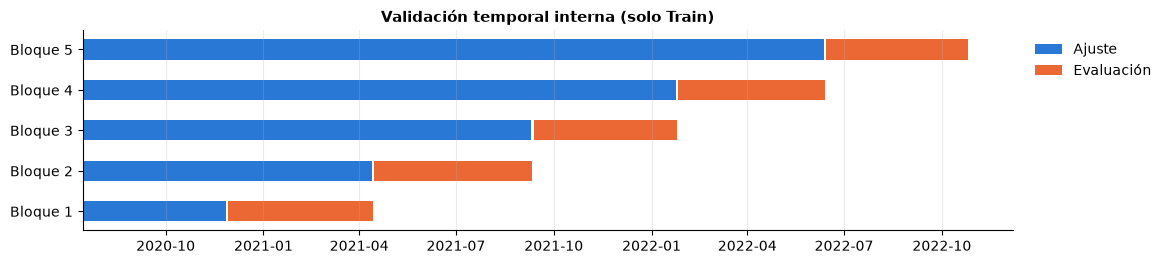

Alpha de Ridge elegido con todas las candidatas: 100.0


In [9]:
cv = pp.validacion_interna(cfg)
fig, ax = plt.subplots(figsize=(12, 2.6))
for i, (ajuste, evaluacion) in enumerate(cv.split(X_tr)):
    ax.barh(i, X_tr.index[ajuste[-1]] - X_tr.index[ajuste[0]], left=X_tr.index[ajuste[0]],
            color="#2a78d6", height=0.5, label="Ajuste" if i == 0 else None)
    ax.barh(i, X_tr.index[evaluacion[-1]] - X_tr.index[evaluacion[0]], left=X_tr.index[evaluacion[0]],
            color="#eb6834", height=0.5, label="Evaluación" if i == 0 else None)
ax.set_yticks(range(cfg.n_splits), [f"Bloque {i + 1}" for i in range(cfg.n_splits)])
ax.set_title("Validación temporal interna (solo Train)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", alpha=0)
plt.show()

alpha = pp.elegir_alpha_ridge(X_tr, y_tr, cfg)
print(f"Alpha de Ridge elegido con todas las candidatas: {alpha}")

In [10]:
def graficar_curva(curva, titulo):
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.errorbar(curva["k"], curva["mae_interno"], yerr=curva["error_estandar"], marker="o", ms=4,
                color="#2a78d6", ecolor="#86b6ef", capsize=3)
    elegido = curva[curva["elegido"]].iloc[0]
    minimo = curva.loc[curva["mae_interno"].idxmin()]
    ax.axhline(minimo["mae_interno"] + minimo["error_estandar"], color="#52514e", ls=":", lw=1,
               label="mínimo + 1 error estándar")
    ax.scatter([elegido["k"]], [elegido["mae_interno"]], s=90, color="#eb6834", zorder=5,
               label=f"elegido: k = {int(elegido['k'])}")
    ax.set_xscale("log")
    ax.set_xlabel("k (primeras variables del ranking)")
    ax.set_ylabel("MAE interno (kW)")
    ax.set_title(titulo)
    ax.legend(frameon=False)
    plt.show()

def graficar_ranking(tabla, columna, titulo, n=20, elegidas=()):
    top = tabla.head(n).iloc[::-1]
    colores = ["#2a78d6" if c in elegidas else "#b7d3f6" for c in top["columna"]]
    fig, ax = plt.subplots(figsize=(9, 0.28 * n + 1))
    ax.barh([corto(c) for c in top["columna"]], top[columna], color=colores, height=0.7)
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0)
    plt.show()

resultados = {}

## 3. Mutual Information

La información mutua mide cuánto reduce cada variable, **por separado**, la incertidumbre sobre `y`. Detecta relaciones no lineales, pero no tiene en cuenta la redundancia: dos variables casi iguales reciben puntajes parecidos.

Para decidir cuántas conservar se recorre el ranking y se mide el MAE interno de Ridge con las primeras *k*. Se elige el *k* más chico cuyo MAE no supera el mínimo más un error estándar (**regla de un error estándar**): ante resultados equivalentes, se prefiere el subconjunto más simple.

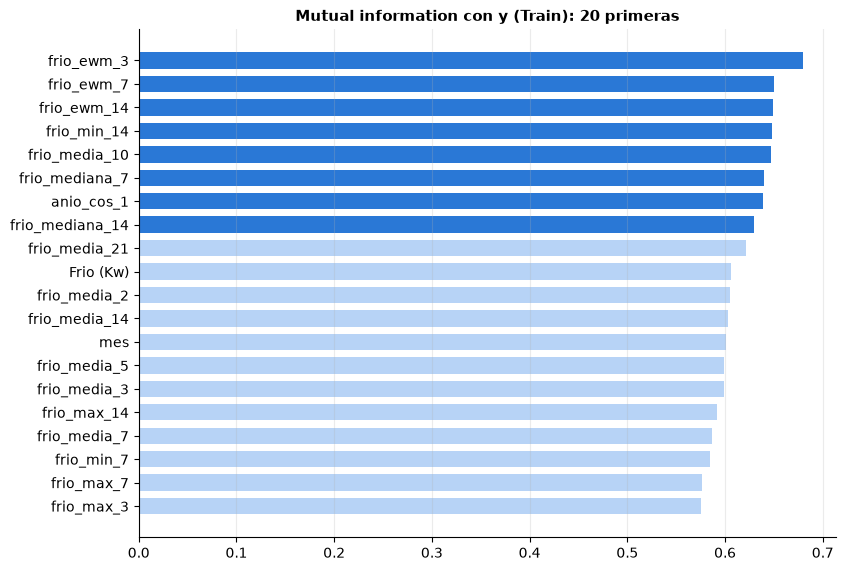

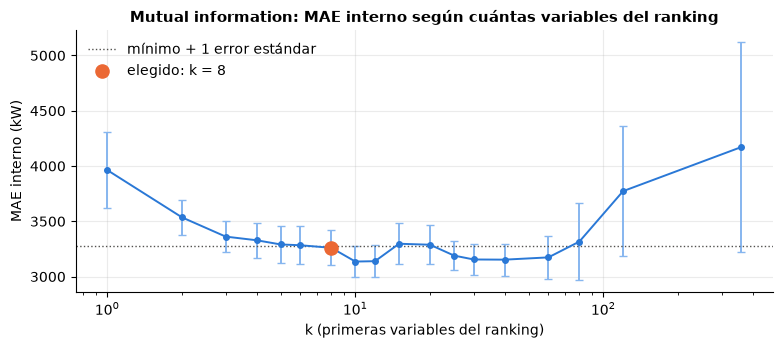

Elegidas: ['frio_ewm_3', 'frio_ewm_7', 'frio_ewm_14', 'frio_min_14', 'frio_media_10', 'frio_mediana_7', 'anio_cos_1', 'frio_mediana_14']


In [11]:
resultados["mutual_information"] = r = pp.metodo_mutual_information(X_tr, y_tr, alpha, cfg)
graficar_ranking(r.tabla, "puntaje", "Mutual information con y (Train): 20 primeras", elegidas=r.columnas)
graficar_curva(r.curva, "Mutual information: MAE interno según cuántas variables del ranking")
print("Elegidas:", [corto(c) for c in r.columnas])

## 4. Ridge

Ridge ajusta todas las candidatas a la vez con penalización L2; con variables estandarizadas, el tamaño del coeficiente indica cuánto pesa cada una **dadas las demás**. Con variables muy correlacionadas, Ridge reparte el peso entre ellas, así que el ranking es menos estable que el de Lasso para elegir una sola de cada grupo. La cantidad se decide con la misma curva y la misma regla que en Mutual Information.

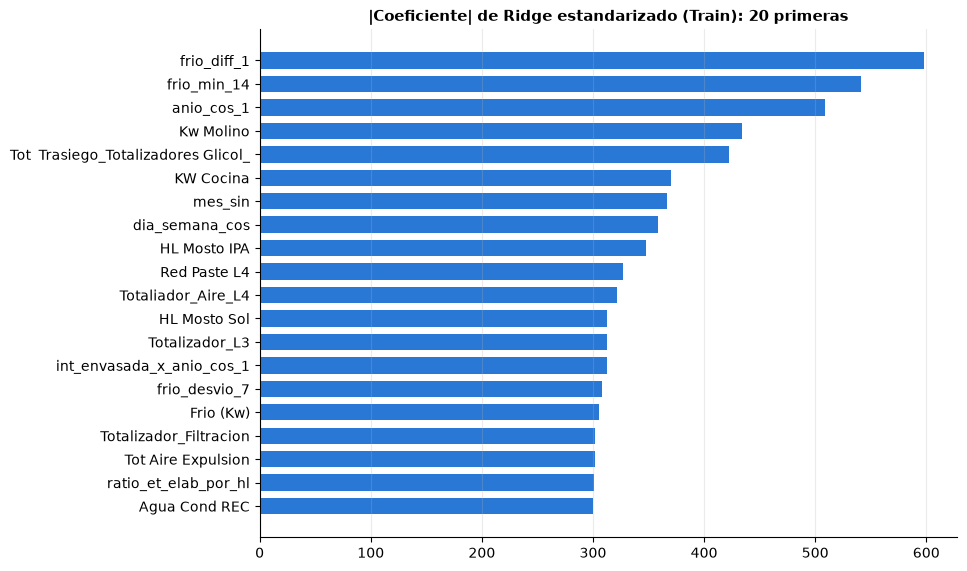

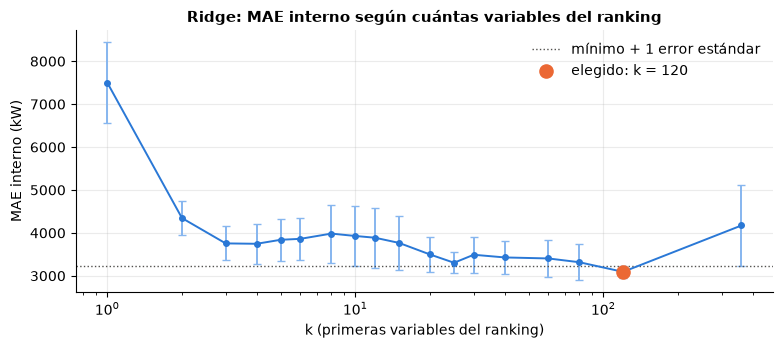

,columna,coeficiente
0,frio_diff_1,597.9
1,frio_min_14,540.9
2,anio_cos_1,-509.2
3,Kw Molino,433.8
4,Tot Trasiego_Totalizadores Glicol_,422.5
...,...,...
115,Totalizador Bba P4,-129.2
116,frio_min_7,128.9
117,EE CO2 / Hl,128.8
118,HL Mosto Roja,127.1


In [12]:
resultados["ridge"] = r = pp.metodo_ridge(X_tr, y_tr, alpha, cfg)
graficar_ranking(r.tabla, "puntaje", "|Coeficiente| de Ridge estandarizado (Train): 20 primeras", elegidas=r.columnas)
graficar_curva(r.curva, "Ridge: MAE interno según cuántas variables del ranking")
display(r.tabla.head(len(r.columnas))[["columna", "coeficiente"]].assign(columna=lambda d: d["columna"].map(corto)).round(1))

## 5. Lasso

Lasso (penalización L1) lleva coeficientes exactamente a cero: la selección es parte del ajuste. `LassoCV` elige el alpha con la misma validación temporal interna. Ante variables correlacionadas tiende a quedarse con una del grupo.

Alpha de Lasso: 176.41 | variables con coeficiente no nulo: 41


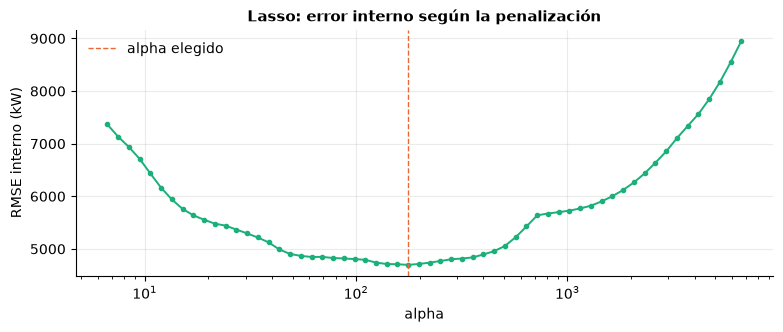

,columna,coeficiente
0,Frio (Kw),1968.0
1,anio_cos_1,-1749.3
2,frio_media_10,891.3
3,frio_min_14,756.2
4,Meta ET Planta,-484.2
5,KW Secador Kaeser,291.7
6,bin_frio_q1,-275.4
7,ratio_agua_bodega_por,-262.0
8,mes_sin,256.1
9,ET Servicios / Hl,-239.1


In [13]:
resultados["lasso"] = r = pp.metodo_lasso(X_tr, y_tr, alpha, cfg)
print(f"Alpha de Lasso: {r.detalle['alpha']:.2f} | variables con coeficiente no nulo: {len(r.columnas)}")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(r.curva["alpha"], r.curva["rmse_interno"], color="#1baf7a", marker="o", ms=3)
ax.axvline(r.detalle["alpha"], color="#eb6834", ls="--", lw=1, label="alpha elegido")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("RMSE interno (kW)")
ax.set_title("Lasso: error interno según la penalización")
ax.legend(frameon=False)
plt.show()
display(r.tabla.head(len(r.columnas))[["columna", "coeficiente"]].assign(columna=lambda d: d["columna"].map(corto)).round(1))

## 6. Forward selection

Empieza sin variables y en cada paso agrega la que más baja el MAE interno de Ridge **junto con las ya elegidas**. A diferencia de los rankings, tiene en cuenta la redundancia: una variable que repite información de las anteriores no mejora el error y no entra. Se detiene cuando la mejora es menor a 5 kW.

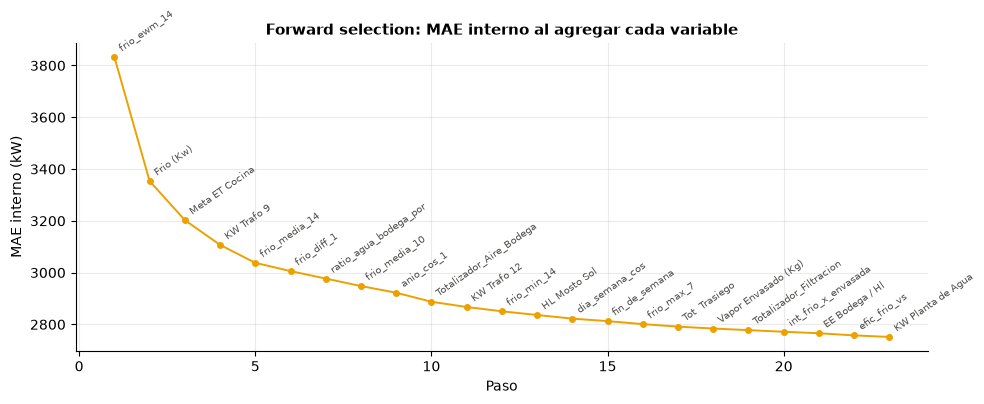

,paso,candidata,mae_interno,mejora_kw,agregada
0,1,frio_ewm_14,3833.0,inf,True
1,2,Frio (Kw),3353.6,479.4,True
2,3,Meta ET Cocina,3202.9,150.8,True
3,4,KW Trafo 9,3107.0,95.8,True
4,5,frio_media_14,3037.8,69.3,True
5,6,frio_diff_1,3005.8,32.0,True
6,7,ratio_agua_bodega_por,2977.0,28.8,True
7,8,frio_media_10,2948.0,29.0,True
8,9,anio_cos_1,2922.3,25.7,True
9,10,Totalizador_Aire_Bodega,2887.4,34.9,True


In [14]:
resultados["forward"] = r = pp.metodo_forward(X_tr, y_tr, alpha, cfg)
recorrido = r.curva
agregadas = recorrido[recorrido["agregada"]]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(agregadas["paso"], agregadas["mae_interno"], marker="o", ms=4, color="#eda100")
for _, fila in agregadas.iterrows():
    ax.annotate(corto(fila["candidata"], 26), (fila["paso"], fila["mae_interno"]), fontsize=7,
                rotation=35, xytext=(2, 4), textcoords="offset points", color="#52514e")
ax.set_xlabel("Paso")
ax.set_ylabel("MAE interno (kW)")
ax.set_title("Forward selection: MAE interno al agregar cada variable")
plt.show()
display(recorrido.assign(candidata=recorrido["candidata"].map(corto)).round(1))

## 7. Coincidencias entre métodos

Una variable que eligen varios métodos con criterios distintos es una candidata más robusta. Además del subconjunto de cada método se arma un **consenso**: las variables elegidas por al menos dos métodos.

In [15]:
subconjuntos = pp.subconjuntos_a_comparar(resultados, list(X_tr.columns))

def marcar(tabla):
    # ✓ en las columnas booleanas (una por método); el resto queda igual.
    return tabla.apply(lambda s: s.map({True: "✓", False: ""}) if s.dtype == bool else s)

elegidas = sorted({c for r in resultados.values() for c in r.columnas})
votos = pd.DataFrame({m: [c in r.columnas for c in elegidas] for m, r in resultados.items()}, index=elegidas)
votos["n_metodos"] = votos.sum(axis=1)
votos = votos.sort_values("n_metodos", ascending=False, kind="stable")
votos.index = votos.index.map(corto)
display(marcar(votos[votos["n_metodos"] >= 2]))
print(f"Variables elegidas por algún método: {len(votos)} | por al menos dos: {(votos['n_metodos'] >= 2).sum()}")

# Cuántas variables de cada familia eligió cada método.
por_familia = pd.DataFrame({m: familia[r.columnas].value_counts() for m, r in resultados.items()})
por_familia = por_familia.reindex(familia.value_counts().index).fillna(0).astype(int)
por_familia.insert(0, "candidatas", familia.value_counts())
print("\nVariables elegidas por familia:")
display(por_familia)

# ¿Qué frío, qué calendario y qué variables creadas eligió cada método?
derivadas = [c for c in X_tr.columns if familia[c] != "preprocesamiento" or c == pp.COL_FRIO]
tabla_derivadas = pd.DataFrame({m: [c in r.columnas for c in derivadas] for m, r in resultados.items()},
                               index=derivadas)
tabla_derivadas["n_metodos"] = tabla_derivadas.sum(axis=1)
tabla_derivadas.insert(0, "familia", familia[derivadas].replace({"preprocesamiento": "frío de D"}))
tabla_derivadas = tabla_derivadas[tabla_derivadas["n_metodos"] > 0].sort_values("n_metodos", ascending=False, kind="stable")
tabla_derivadas.index = tabla_derivadas.index.map(corto)
print("\nFrío, derivadas del frío, calendario y variables creadas elegidas por al menos un método:")
display(marcar(tabla_derivadas))

metodos = list(resultados)
jaccard = pd.DataFrame(index=metodos, columns=metodos, dtype=float)
for a in metodos:
    for b in metodos:
        A, B = set(resultados[a].columnas), set(resultados[b].columnas)
        jaccard.loc[a, b] = len(A & B) / len(A | B)
print("\nSolapamiento entre métodos (Jaccard):")
display(jaccard.round(2))

,mutual_information,ridge,lasso,forward,n_metodos
anio_cos_1,✓,✓,✓,✓,4
frio_media_10,✓,✓,✓,✓,4
frio_min_14,✓,✓,✓,✓,4
Frio (Kw),,✓,✓,✓,3
HL Mosto Sol,,✓,✓,✓,3
KW Trafo 12,,✓,✓,✓,3
Totalizador_Aire_Bodega,,✓,✓,✓,3
Totalizador_Filtracion,,✓,✓,✓,3
dia_semana_cos,,✓,✓,✓,3
frio_diff_1,,✓,✓,✓,3


Variables elegidas por algún método: 135 | por al menos dos: 42

Variables elegidas por familia:


,candidatas,mutual_information,ridge,lasso,forward
familia,,,,,
preprocesamiento,269,0,77,27,11
derivada del frío,35,7,24,3,6
binning,17,0,2,4,0
interacción,14,0,5,1,1
ratio entre áreas,11,0,3,3,1
calendario,6,0,5,2,2
ciclo anual,4,1,2,1,1
eficiencia vs meta,4,0,2,0,1



Frío, derivadas del frío, calendario y variables creadas elegidas por al menos un método:


,familia,mutual_information,ridge,lasso,forward,n_metodos
frio_media_10,derivada del frío,✓,✓,✓,✓,4
frio_min_14,derivada del frío,✓,✓,✓,✓,4
anio_cos_1,ciclo anual,✓,✓,✓,✓,4
Frio (Kw),frío de D,,✓,✓,✓,3
frio_ewm_14,derivada del frío,✓,✓,,✓,3
frio_diff_1,derivada del frío,,✓,✓,✓,3
dia_semana_cos,calendario,,✓,✓,✓,3
ratio_agua_bodega_por,ratio entre áreas,,✓,✓,✓,3
frio_media_14,derivada del frío,,✓,,✓,2
frio_mediana_7,derivada del frío,✓,✓,,,2



Solapamiento entre métodos (Jaccard):


,mutual_information,ridge,lasso,forward
mutual_information,1.00,0.06,0.07,0.15
ridge,0.06,1.00,0.26,0.13
lasso,0.07,0.26,1.00,0.23
forward,0.15,0.13,0.23,1.00


## 8. Comparación en Validation

Cada subconjunto se ajusta con **todo Train** y se evalúa una sola vez en Validation, con dos estimadores fijos para no favorecer a una familia de modelos: Ridge (con el alpha elegido en la sección 2) y un Random Forest con hiperparámetros fijos y semilla 42. Gana el **menor MAE promedio** entre los dos; ante un empate, el de menos columnas.

Los baselines obligatorios se calculan sobre las mismas filas de Validation: **persistencia** (mañana = hoy) y **media de 7 días** (promedio de D-6 a D).

In [16]:
comparacion = pp.comparar_en_validation(subconjuntos, X_tr, y_tr, X_val, y_val, alpha, cfg)
baselines = pp.baselines_validation(candidatas.loc[X_val.index], y_val)  # usa columnas que el filtro quita
display(pd.concat([comparacion, baselines], ignore_index=True).round(1))
ganador = comparacion.iloc[0]["subconjunto"]
mejor_baseline = baselines["mae_val_promedio"].min()
mejora = 1 - comparacion.iloc[0]["mae_val_promedio"] / mejor_baseline
print(f"Ganador: {ganador} ({len(subconjuntos[ganador])} variables) | "
      f"mejora sobre el mejor baseline: {mejora:.1%}")

,subconjunto,columnas,mae_val_ridge,mae_val_random_forest,mae_val_promedio
0,forward,23,2300.5,2341.2,2320.9
1,consenso_2_metodos,42,2442.0,2316.0,2379.0
2,mutual_information,8,2240.6,2690.2,2465.4
3,ridge,120,2454.1,2508.6,2481.3
4,lasso,41,2561.7,2401.3,2481.5
5,todas,360,3227.5,2495.0,2861.3
6,baseline_persistencia,0,NaN,NaN,2727.1
7,baseline_media_7,0,NaN,NaN,2398.3


Ganador: forward (23 variables) | mejora sobre el mejor baseline: 3.2%


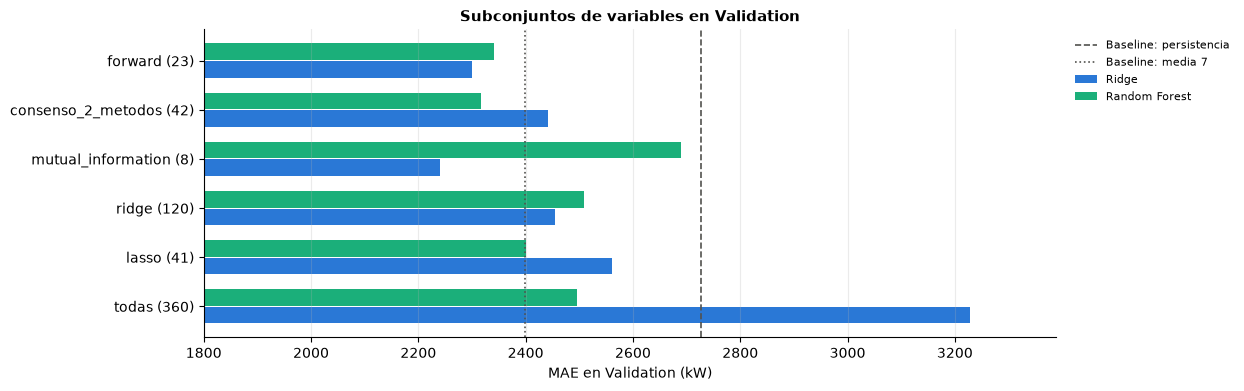

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
orden = comparacion.sort_values("mae_val_promedio", ascending=False)
pos = np.arange(len(orden))
ax.barh(pos - 0.18, orden["mae_val_ridge"], height=0.34, color="#2a78d6", label="Ridge")
ax.barh(pos + 0.18, orden["mae_val_random_forest"], height=0.34, color="#1baf7a", label="Random Forest")
for _, fila in baselines.iterrows():
    ax.axvline(fila["mae_val_promedio"], color="#52514e", ls="--" if "persistencia" in fila["subconjunto"] else ":",
               lw=1.2, label=fila["subconjunto"].replace("baseline_", "Baseline: ").replace("_", " "))
ax.set_yticks(pos, [f"{s} ({n})" for s, n in zip(orden["subconjunto"], orden["columnas"])])
ax.set_xlim(left=1800)
ax.set_xlabel("MAE en Validation (kW)")
ax.set_title("Subconjuntos de variables en Validation")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(axis="y", alpha=0)
plt.show()

### 8.1 ¿Aportan las variables creadas?

Hay dos preguntas distintas:

1. **¿Cambia el resultado de la selección?** Se repite todo (alpha, los cuatro métodos y la comparación) sin las variables creadas, con las mismas filas. Agregar candidatas también cambia el alpha de Ridge, que se elige con todas, y forward depende de ese alpha. Por eso un subconjunto puede cambiar aunque no incluya ninguna variable nueva.
2. **¿Cuánto aporta cada familia creada dentro de un subconjunto?** Se quitan sus variables del subconjunto elegido, con el mismo alpha y los mismos estimadores, y se mide el error interno en Train y el error en Validation. También se mide el sesgo medio de Ridge en Validation (predicción − y): un sesgo grande indica que el modelo se corre de nivel.

In [18]:
sin_creadas = familia.index[~familia.isin(CREADAS)].tolist()
alpha_sin, resultados_sin, subconjuntos_sin, comparacion_sin = pp.seleccionar(
    X_tr[sin_creadas], y_tr, X_val[sin_creadas], y_val, cfg)
print(f"Alpha de Ridge: {alpha_sin} sin las variables creadas | {alpha} con ellas")

efecto = (comparacion.set_index("subconjunto")[["columnas", "mae_val_promedio"]].add_suffix(" (con creadas)")
          .join(comparacion_sin.set_index("subconjunto")[["columnas", "mae_val_promedio"]].add_suffix(" (sin creadas)")))
efecto.insert(1, "creadas elegidas", [sum(familia[c] in CREADAS for c in subconjuntos[s]) for s in efecto.index])
efecto["diferencia en MAE (con − sin)"] = efecto["mae_val_promedio (con creadas)"] - efecto["mae_val_promedio (sin creadas)"]
display(efecto.round(1))

Alpha de Ridge: 100.0 sin las variables creadas | 100.0 con ellas


,columnas (con creadas),creadas elegidas,mae_val_promedio (con creadas),columnas (sin creadas),mae_val_promedio (sin creadas),diferencia en MAE (con − sin)
subconjunto,,,,,,
forward,23,4,2320.9,21,2304.3,16.5
consenso_2_metodos,42,7,2379.0,38,2407.3,-28.3
mutual_information,8,1,2465.4,5,2437.7,27.7
ridge,120,14,2481.3,120,2417.8,63.5
lasso,41,9,2481.5,30,2402.1,79.4
todas,360,50,2861.3,310,2766.3,95.0


In [19]:
from sklearn.metrics import mean_absolute_error

def medir(columnas):
    # Error interno (Train), MAE en Validation de cada estimador y sesgo de Ridge en Validation.
    fila = {"MAE interno": pp.mae_interno(X_tr, y_tr, columnas, alpha, cfg)[0]}
    for est in cfg.estimadores_validacion:
        pred = pp.crear_estimador(est, alpha).fit(X_tr[columnas], y_tr).predict(X_val[columnas])
        fila[f"MAE val {est}"] = mean_absolute_error(y_val, pred)
        if est == "ridge":
            fila["sesgo val ridge"] = float(np.mean(pred - y_val))
    return fila

filas = []
for nombre, columnas in subconjuntos.items():
    creadas_en = [c for c in columnas if familia[c] in CREADAS]
    if nombre == "todas" or not creadas_en:
        continue
    quitas = {"(ninguna)": [], "todas las creadas": creadas_en}
    for fam in CREADAS:
        de_la_familia = [c for c in creadas_en if familia[c] == fam]
        if de_la_familia and len(de_la_familia) < len(creadas_en):
            quitas[f"{fam} ({len(de_la_familia)})"] = de_la_familia
    for etiqueta, quitar in quitas.items():
        filas.append({"subconjunto": nombre, "se quita": etiqueta,
                      **medir([c for c in columnas if c not in quitar])})
ablacion = pd.DataFrame(filas).set_index(["subconjunto", "se quita"])
display(ablacion.round(1))

MAE interno  MAE val ridge  sesgo val ridge  MAE val random_forest
subconjunto        se quita                                                                                  
mutual_information (ninguna)                    3260.3         2240.6            477.3                 2690.2
                   todas las creadas            3274.1         2236.7            416.1                 2614.4
ridge              (ninguna)                    3091.8         2454.1            848.4                 2508.6
                   todas las creadas            3196.9         2502.2           1206.4                 2524.6
                   ciclo anual (2)              3084.6         2429.5            896.9                 2513.5
                   binning (2)                  3114.5         2465.3            877.6                 2512.9
                   interacción (5)              3194.5         2622.8           1363.2                 2364.2
                   ratio entre áreas (3)        3094.5         2445.3            829.1                 2522.6
                   eficiencia vs meta (2)       3112.5         2393.7            625.6                 2545.9
lasso              (ninguna)                    2856.9         2561.7           -268.6                 2401.3
                   todas las creadas            3064.1         2484.2             18.1                 2361.4
                   ciclo anual (1)              2940.8         2550.7              4.6                 2360.7
                   binning (4)                  2944.3         2521.3           -275.5                 2396.1
                   interacción (1)              2844.9         2536.2           -131.6                 2400.1
                   ratio entre áreas (3)        2911.4         2544.8           -317.2                 2378.2
forward            (ninguna)                    2751.5         2300.5            220.1                 2341.2
                   todas las creadas            2870.7         2217.8            204.9                 2317.0
                   ciclo anual (1)              2873.9         2212.4            358.4                 2272.6
                   interacción (1)              2756.8         2298.6            238.6                 2331.7
                   ratio entre áreas (1)        2772.0         2305.5            110.0                 2376.1
                   eficiencia vs meta (1)       2763.3         2306.4            105.4                 2370.6
consenso_2_metodos (ninguna)                    2896.9         2442.0            190.7                 2316.0
                   todas las creadas            2931.3         2345.1            227.7                 2382.1
                   ciclo anual (1)              2931.6         2402.8            402.8                 2317.2
                   binning (2)                  2900.2         2405.8            136.1                 2313.6
                   interacción (1)              2895.2         2409.8            381.5                 2308.3
                   ratio entre áreas (2)        2906.0         2434.5            127.6                 2349.6
                   eficiencia vs meta (1)       2922.0         2414.7            -86.6                 2341.1

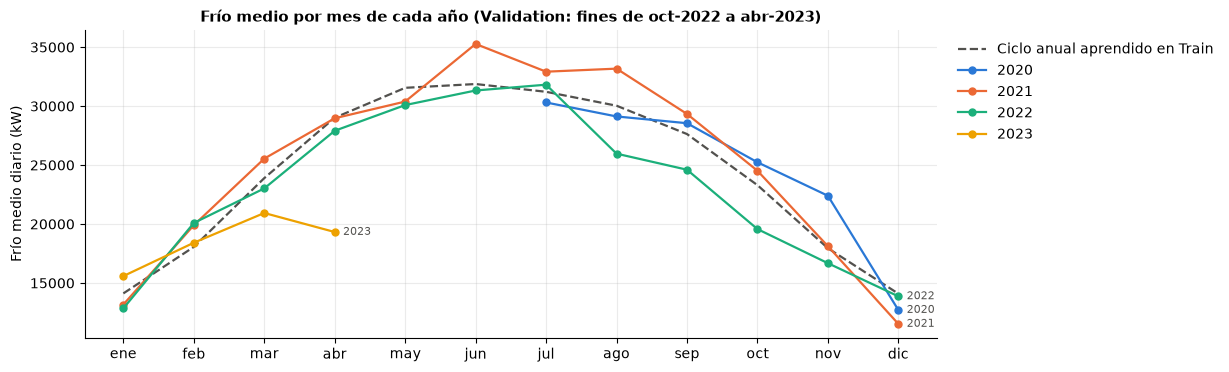

año,2020,2021,2022,2023
mes,,,,
1,NaN,13171.0,12848.0,15585.0
2,NaN,19900.0,20088.0,18412.0
3,NaN,25544.0,23019.0,20934.0
4,NaN,28967.0,27907.0,19320.0
5,NaN,30384.0,30086.0,NaN
6,NaN,35270.0,31323.0,NaN
7,30306.0,32917.0,31814.0,NaN
8,29121.0,33175.0,25966.0,NaN
9,28548.0,29332.0,24605.0,NaN


In [20]:
# ¿Se repite en Validation la estación de Train? Frío medio por mes de cada año (Test no se lee).
frio_hasta_val = historial.loc[:X_val.index.max(), pp.COL_FRIO]
por_mes = (frio_hasta_val.groupby([frio_hasta_val.index.year, frio_hasta_val.index.month]).mean()
           .unstack(0).rename_axis(index="mes", columns="año"))
SERIE_ANIOS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # orden fijo de la paleta categórica

# Patrón aprendido en Train: regresión del frío sobre el ciclo anual (armónicos 1 y 2).
frio_tr_cal = historial.loc[:fin_train, pp.COL_FRIO]
armonicos = candidatas.loc[frio_tr_cal.index, ["anio_sin_1", "anio_cos_1", "anio_sin_2", "anio_cos_2"]]
A = np.c_[np.ones(len(frio_tr_cal)), armonicos.to_numpy()]
coef = np.linalg.lstsq(A, frio_tr_cal.to_numpy(), rcond=None)[0]
referencia = pd.date_range("2021-01-01", "2021-12-31")
patron = pd.Series(np.c_[np.ones(len(referencia)), pp.variables_ciclo_anual(referencia, (1, 2)).to_numpy()] @ coef,
                   index=referencia).groupby(referencia.month).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(patron.index, patron, color="#52514e", ls="--", lw=1.6, label="Ciclo anual aprendido en Train")
for i, anio in enumerate(por_mes.columns):
    serie = por_mes[anio].dropna()
    ax.plot(serie.index, serie, color=SERIE_ANIOS[i], marker="o", ms=5, lw=1.6, label=str(anio))
    ax.annotate(str(anio), (serie.index[-1], serie.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                fontsize=8, color="#52514e", va="center")
ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("Frío medio diario (kW)")
ax.set_title("Frío medio por mes de cada año (Validation: fines de oct-2022 a abr-2023)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
display(por_mes.round(0))

**Lectura:**

* **El alpha no cambia** (100 con y sin las variables creadas), así que las diferencias se deben a las variables.
* **El efecto de las variables creadas es chico:** cambian el MAE promedio de cada subconjunto en menos de 100 kW. Mejoran al consenso (28 kW) y empeoran levemente a forward (17 kW), Mutual Information (28 kW), Ridge (64 kW) y Lasso (79 kW).
* **Dentro de forward, el ciclo anual es lo que no se sostiene:** quitar `anio_cos_1` sube el error interno 122 kW, pero baja el MAE de Validation 88 kW con Ridge y 69 kW con Random Forest.
* **El ratio de agua de bodega y la eficiencia contra la meta ayudan un poco:** dentro de forward, quitarlos empeora a Random Forest (35 y 29 kW) y deja a Ridge casi igual (+5 y +6 kW).
* **Las interacciones dividen a los modelos:** en el subconjunto de Ridge, quitarlas empeora a Ridge en 169 kW y mejora a Random Forest en 144 kW.
* **Sin la maquinaria, el sesgo bajó mucho:** Ridge con el subconjunto forward sobreestimaba 1.466 kW en promedio en la selección anterior y ahora 220 kW.
* **Por qué falla el ciclo anual.** La estación de Validation no repite la de Train: enero de 2023 consumió 15.585 kW de media (12.848 en enero de 2022) y abril de 2023, 19.320 kW (27.907 en 2022). Una onda anual fija, aprendida con 2020-2022, se corre de nivel en ese período.

## 9. Exportación y comparación con el script

`pp.ejecutar_seleccion()` repite todo y devuelve, sin guardar archivos, los rankings y curvas de cada método, los votos por variable, la comparación en Validation y un resumen con la configuración, las fechas y las columnas ganadoras. `src/train_model.py` la recalcula igual para obtener los subconjuntos. Comprobamos que llega al mismo resultado que esta notebook.

In [21]:
resultado_script = pp.ejecutar_seleccion(cfg)
assert resultado_script["ganador"] == ganador
assert resultado_script["subconjuntos"][ganador] == subconjuntos[ganador]
print("El script elige el mismo subconjunto que la notebook.")
print("\nVariables del subconjunto ganador:")
for i, c in enumerate(subconjuntos[ganador], 1):
    print(f"  {i:>2}. {c}")

SELECCIÓN DE VARIABLES
Candidatas: 360 -> 360 tras el filtro de redundancia | Train: 786 filas | Validation: 171 filas
  preprocesamiento: 269 | derivada del frío: 35 | binning: 17 | interacción: 14 | ratio entre áreas: 11 | calendario: 6 | ciclo anual: 4 | eficiencia vs meta: 4
Alpha de Ridge (validación temporal interna): 100.0
  mutual_information  :   8 variables
  ridge               : 120 variables
  lasso               :  41 variables
  forward             :  23 variables
          subconjunto  columnas  mae_val_ridge  mae_val_random_forest  mae_val_promedio
              forward        23         2300.5                 2341.2            2320.9
   consenso_2_metodos        42         2442.0                 2316.0            2379.0
   mutual_information         8         2240.6                 2690.2            2465.4
                ridge       120         2454.1                 2508.6            2481.3
                lasso        41         2561.7                 2401.3       

## 10. Conclusiones

In [22]:
tabla = pd.concat([comparacion, baselines], ignore_index=True)[["subconjunto", "columnas", "mae_val_promedio"]]
tabla["vs mejor baseline"] = (1 - tabla["mae_val_promedio"] / mejor_baseline).map("{:+.1%}".format)
display(tabla.round(1))

,subconjunto,columnas,mae_val_promedio,vs mejor baseline
0,forward,23,2320.9,+3.2%
1,consenso_2_metodos,42,2379.0,+0.8%
2,mutual_information,8,2465.4,-2.8%
3,ridge,120,2481.3,-3.5%
4,lasso,41,2481.5,-3.5%
5,todas,360,2861.3,-19.3%
6,baseline_persistencia,0,2727.1,-13.7%
7,baseline_media_7,0,2398.3,+0.0%


**Qué muestran los resultados:**

* **El frío reciente domina.** Los cuatro métodos eligen la media de 10 cierres, el mínimo de 14 y el ciclo anual (`anio_cos_1`); tres eligen además el frío de hoy, su diferencia con ayer y la media exponencial de 14. Mutual Information se queda solo con ventanas del frío y el ciclo anual (8 variables).
* **De las familias nuevas,** `ratio_agua_bodega_por_hl` lo eligen tres métodos y `efic_frio_vs_meta` dos. Son las dos que en la sección 1.4 aportaban sobre la persistencia.
* **Ningún subconjunto contiene medidores que incluyan al frío:** la EDA los excluyó, y el frío de D entra solo como tal.
* **Ganador: forward** (23 variables, 2.321 kW de MAE promedio: 2.300 con Ridge y 2.341 con Random Forest). Mejora a la media de 7 días (2.398 kW) en 3,2 %. Mutual Information llega a 2.241 kW con Ridge, pero a 2.690 con Random Forest, y el criterio es el promedio de los dos estimadores.
* **Frente a la selección anterior** (383 candidatas, con maquinaria y proxies del frío), forward pasa de 2.545 a 2.321 kW de MAE promedio, y Ridge con forward de 2.761 a 2.300 kW. Excluir los componentes del frío resolvió la mayor parte de la sobreestimación.
* **El filtro de redundancia se probó y se descartó** (sección 1.5): con umbral 0,90 empeora a todos los modelos en Validation.
* **El día de la semana entra:** forward elige `dia_semana_cos` y `fin_de_semana`, coherente con el efecto que la EDA encontró una vez quitada la estación.

**Decisiones para el modelado:**

1. **Que el modelado elija el conjunto.** En `notebooks/modelado.ipynb`, Optuna trata el subconjunto de variables como un hiperparámetro más, con la validación interna en Train, y Validation compara los mejores de cada modelo.
2. **Cada familia creada se puede apagar** desde `ConfigSeleccion` (`armonicos_anuales=()`, `binning=()`, `variables_interaccion=()`, `ratios=()`, `eficiencias=()`).
3. **Frente al cambio de régimen y a la estación distinta de Validation**, la opción más defendible es dar más peso a los meses recientes en el reentrenamiento final, eligiendo cuánto con una evaluación mes a mes sobre Validation.
4. Antes de defender una diferencia entre subconjuntos, medir su variabilidad: con diferencias de alrededor de 100 kW, el ganador puede cambiar por ruido.